# Waterline excursion from timestacks, mapped onto contour-map DEM profiles
csherwood@usgs.gov, 2026-11-13, generated with Claude Opus 5.5

For each timestack (`*.ras.tiff` in the imagery folders; rows = time at 2 Hz, columns = pixel-instrument pixels):

1. **Split** the timestack and the `.pix` file into transects with the ShoreScan routines
   `utils_runup.process_and_split_image` and `utils_runup.split_and_save_pixcoordinates` (a new transect starts where
   consecutive pixels jump by more than `RUNUP['jump']` px).
2. **Rectify** the transect pixels onto the day's DEM (`scan/dems/dem_YYYY-MM-DD.tif`) with the ShoreScan CIRN routines
   (`utils_CIRN.dist_uv_to_xyz`, then ray marching to the DEM in `utils_CIRN.get_elevations`), using the
   calibration valid at the timestack time (`marconi_scan.calib_files`). Profiles go to `scan/runup_profiles.csv`.
3. **Waterline** in each time row: with the color index $c = (R-B)/(R+G+B)$ (sand > 0, foam ≈ 0, water < 0), a pixel is wet
   where $c < f_w\,c_\mathrm{sand}$, with $c_\mathrm{sand}$ from the landward end of the transect and $f_w$ = 0.5. The waterline is the
   last wet pixel before the first run of `n_dry` dry pixels, searching from the seaward end.
4. **Map** the waterline series onto the profile, $z(t)$, and report min, 2nd percentile, median, 98th percentile,
   max, and $4\sigma_z$ (rough significant swash), plus the same relative to the measured water level
   (`eta_*` = `z_*` − water level), the swash-zone slope of the DEM, and the Stockdon et al. (2006) setup and $R_{2\%}$
   levels from `image_scan.csv` for comparison.

This is a rough estimate of the swash range, not a runup analysis. The 98th percentile is of the whole waterline
series (like η2 in `utils_runup.runupStatistics_CHI`), not of the runup maxima ($R_{2\%}$), so it is lower than $R_{2\%}$.
`clip_sea` and `clip_land` give the fraction of time the waterline was at the seaward or landward end of the transect
(the min or max is then truncated).

Requires (beyond the earlier notebooks): rioxarray, utm, geopy, scikit-learn, requests (imported by the ShoreScan
`utils_CIRN.py` and `utils_runup.py`, which must be on the path with `marconi_scan.py`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import marconi_scan as ms
import marconi_runup as mr
import utils_runup

# --- config
PROJ = Path(r'F:\crs\proj\2026_wl_dems')
IMG_ROOT = Path(r'F:\crs\proj\marconi_imagery')
STATIONS = ['caco-03']
CAL_DIR = Path(r'F:\crs\proj\marconi_imagery\calibration_parameters')
CAL_TABLE = CAL_DIR / 'calib_parameter_table.csv'
PIX_DIR = Path(r'F:\crs\proj\marconi_imagery\pixel_locations')
PIX_FILES = {c: PIX_DIR / f'{c}_timestack.pix' for c in ['c1', 'c2']}
CAMERA_SETTINGS = None                 # ShoreScan camera_settings.json for date-dependent .pix files (overrides PIX_FILES)
WAVES = PROJ / 'nanopod_waves' / 'sig1000_waves_ALL1.csv'
OUT_DIR = PROJ / 'scan'
SCAN_CSV = OUT_DIR / 'image_scan.csv'
DEM_DIR = OUT_DIR / 'dems'
FIG_DIR = PROJ / 'fig'
STACK_FIG_DIR = FIG_DIR / 'runup_stacks'
DAY_FIG_DIR = FIG_DIR / 'runup_profiles'
FIRST_DAY, LAST_DAY = None, None       # e.g. '2025-01-20', '2025-03-08'; None = the nanopod record in WAVES
RUNUP = mr.RUNUP | {}                  # e.g. {'reverse': {'c1': True, 'c2': False}, 'wet_frac': 0.4}

for d in [STACK_FIG_DIR, DAY_FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)
scan = pd.read_csv(SCAN_CSV, parse_dates=['time'])
table = ms.read_calib_table(CAL_TABLE)
cam_set = utils_runup.get_camera_settings(CAMERA_SETTINGS) if CAMERA_SETTINGS else None
waves = pd.read_csv(WAVES, parse_dates=['time'])
t0 = pd.Timestamp(FIRST_DAY) if FIRST_DAY else waves.time.min()
t1 = pd.Timestamp(LAST_DAY) + pd.Timedelta('1D') if LAST_DAY else waves.time.max()
ts = mr.list_timestacks(IMG_ROOT, STATIONS)
ts = ts[(ts.time >= t0) & (ts.time <= t1)].reset_index(drop=True)
print(ts.groupby('camera').size(), ts.time.min(), ts.time.max())

camera
c1    1125
c2    1122
dtype: int64 2024-12-09 18:00:00 2025-02-04 23:00:00


## Check the pixel instruments against the timestacks
Timestacks with no calibration are skipped on purpose (status `no calibration`): at CACO03 a guy wire broke on
2025-01-04 and the cameras moved, then moved again when it was reattached on 2025-01-07.

For each camera and calibration period, `fig/pix_transects_<camera>_<EO file>.png` shows the `.pix` transects, numbered,
on a sharp timex image from that period (closest to local noon). The timestack width must equal the number of `.pix`
rows (printed below, and shown in `fig/pix_check_<camera>.png` with the transect boundaries on a timestack). A new
transect starts where consecutive pixels jump by more than `RUNUP['jump']` px (100, ShoreScan's rule). If two transects
stay merged because their ends are close together, set `RUNUP['jump_rel']` (e.g. 8) to also split at jumps larger than
that multiple of the typical pixel step.

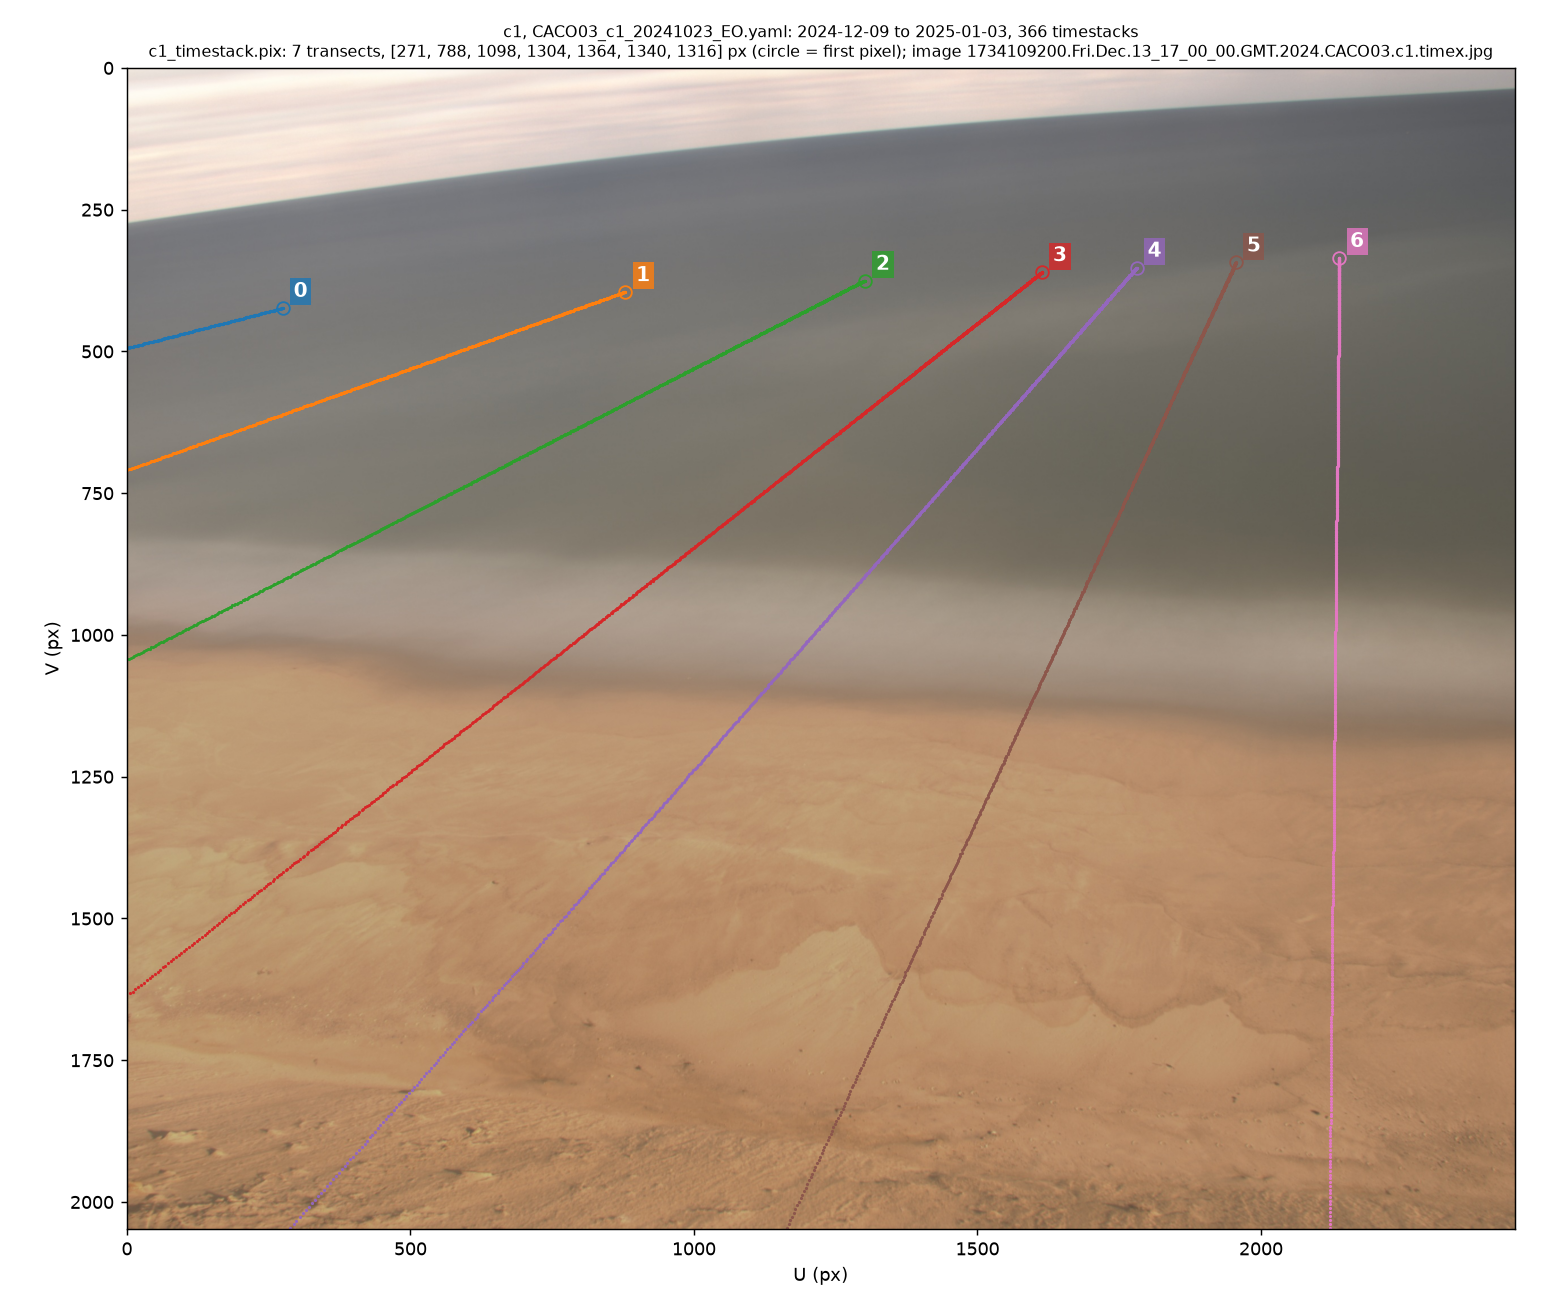

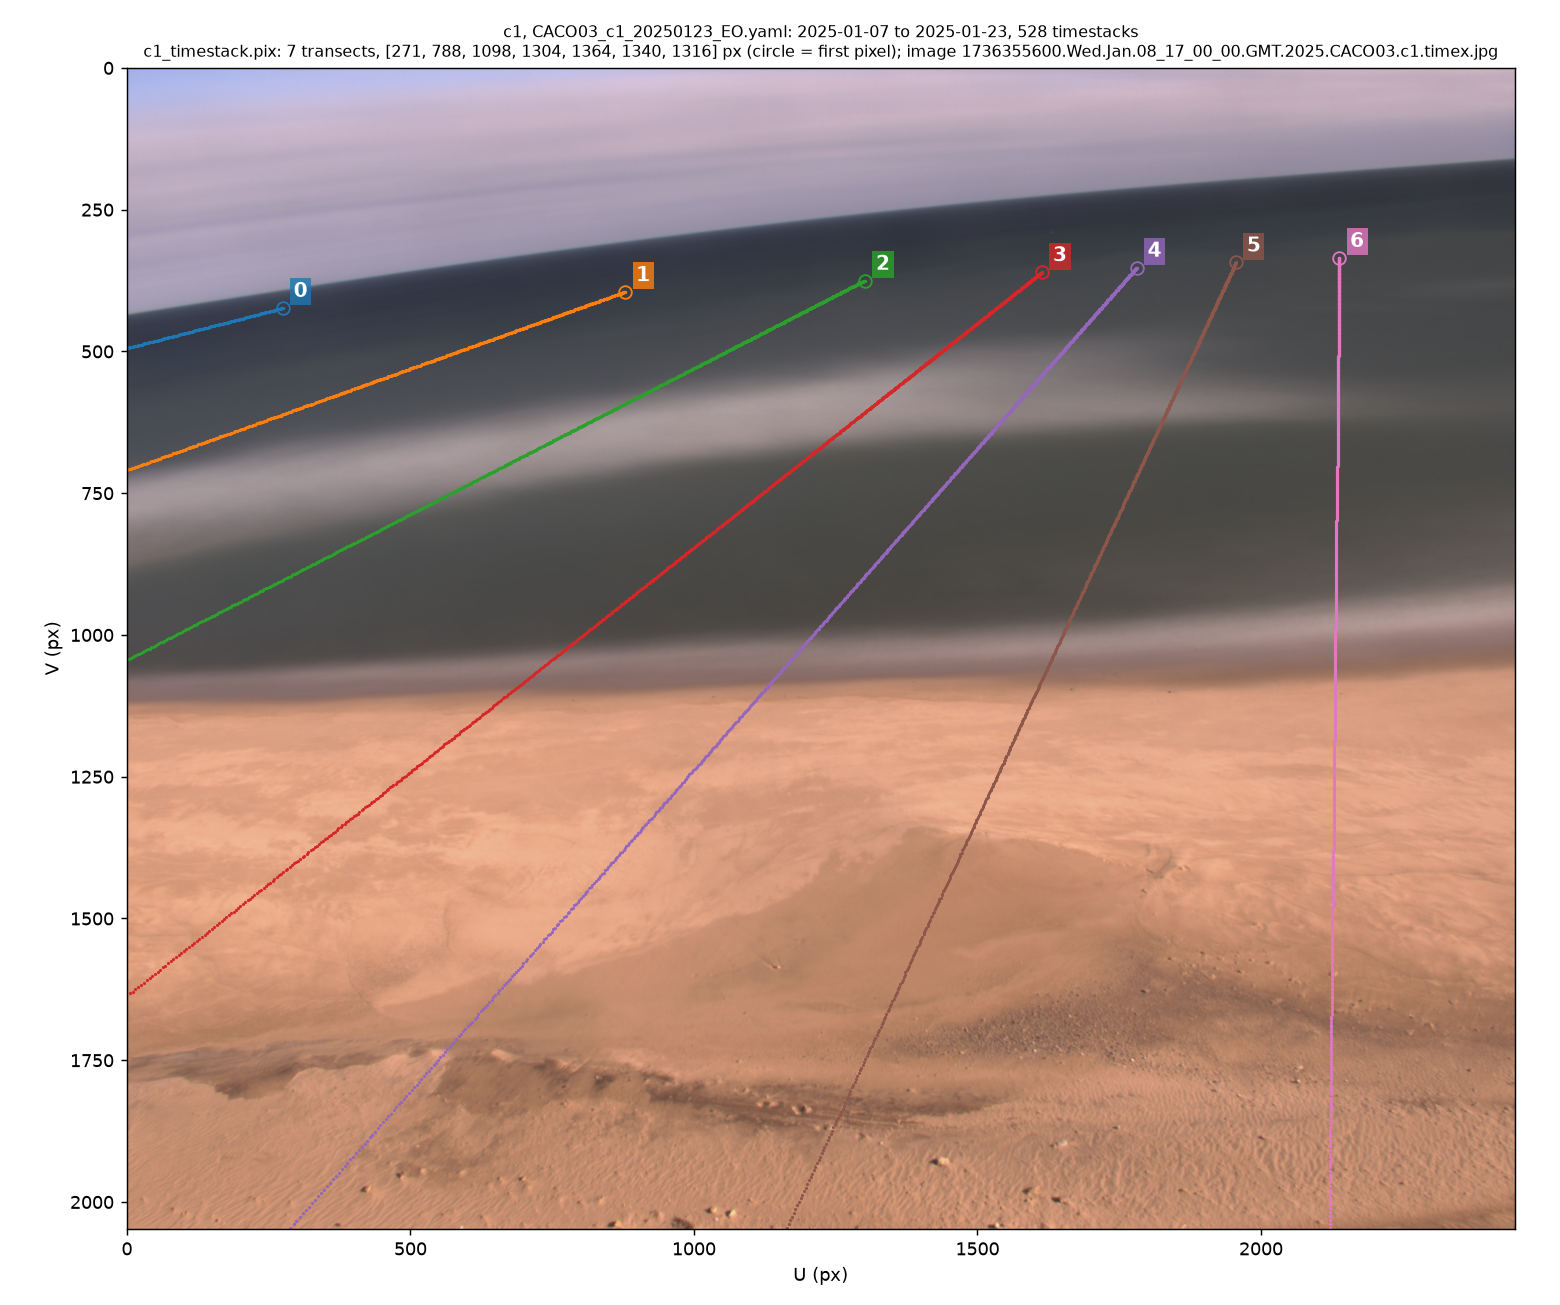

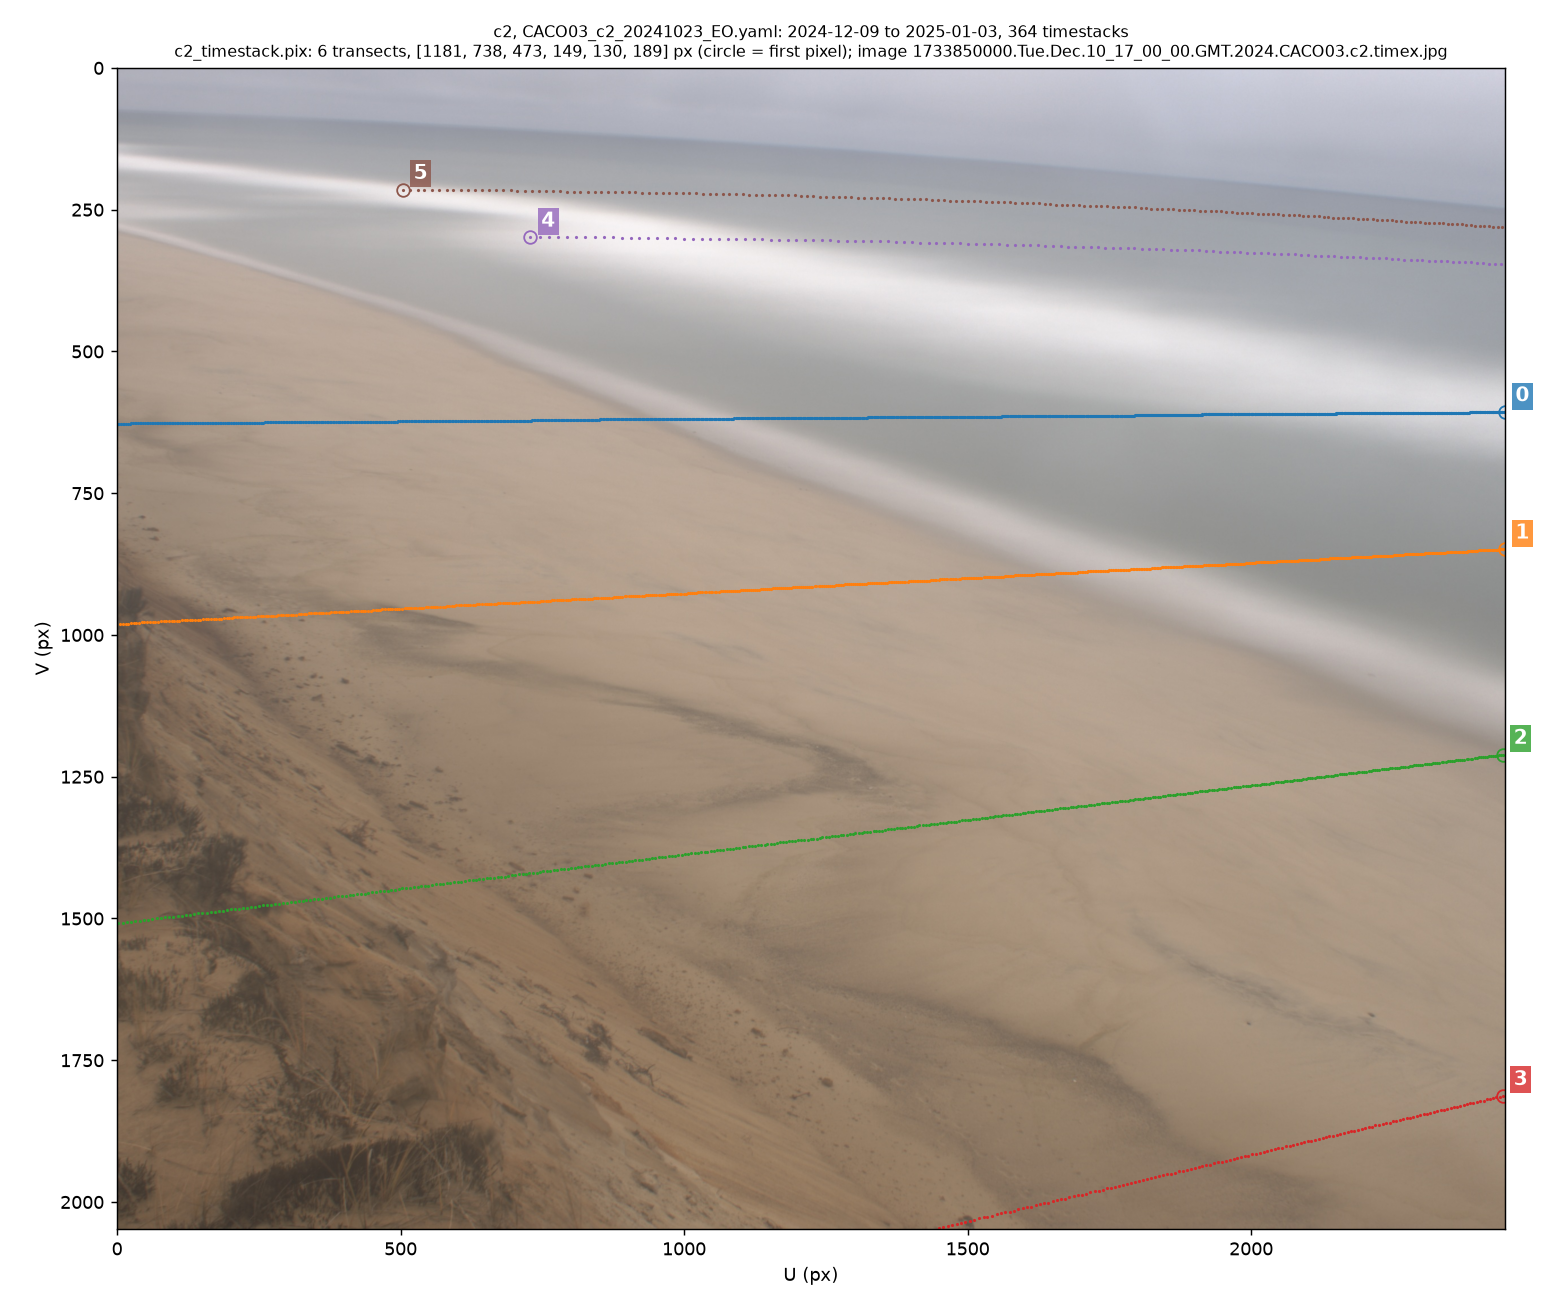

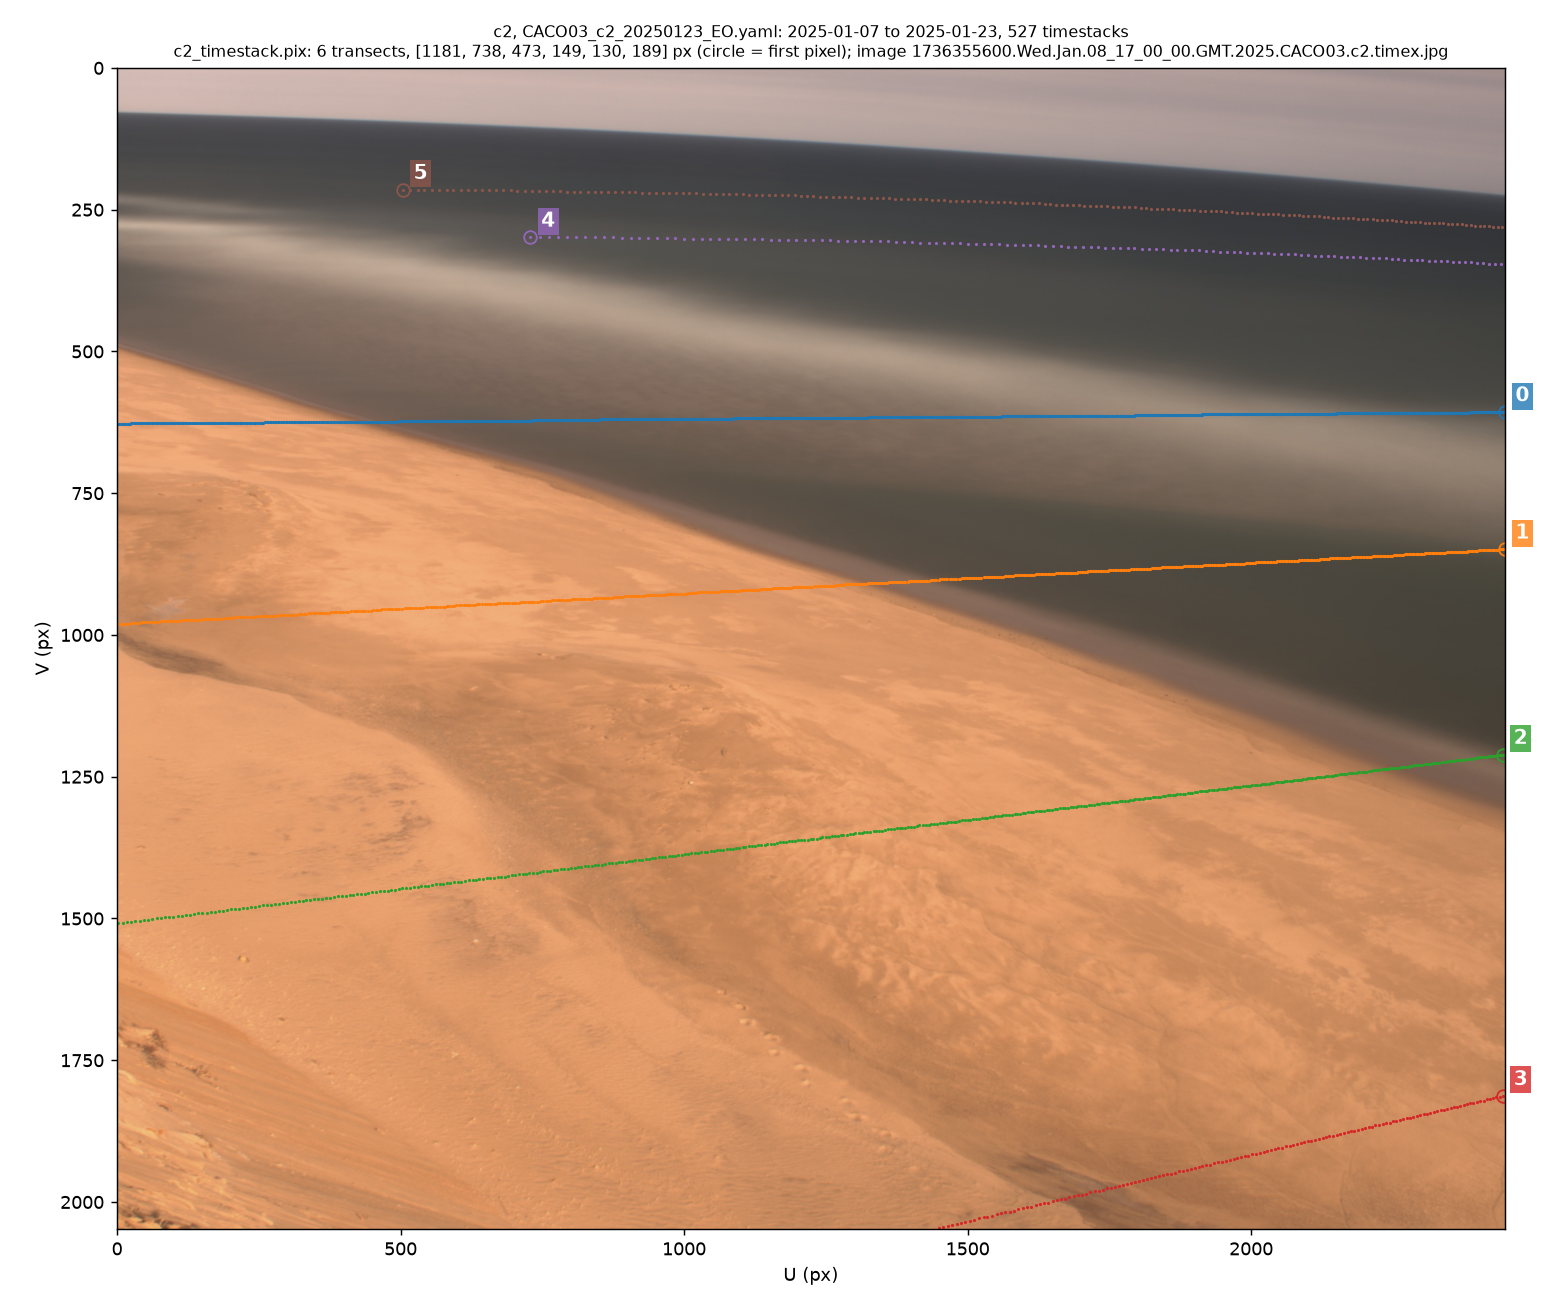

c1: timestack 7481 columns; c1_timestack.pix 7481 pixels; transects [271, 788, 1098, 1304, 1364, 1340, 1316]
c2: timestack 2541 columns; c2_timestack.pix 2860 pixels; transects [1181, 738, 473, 149, 130, 189]


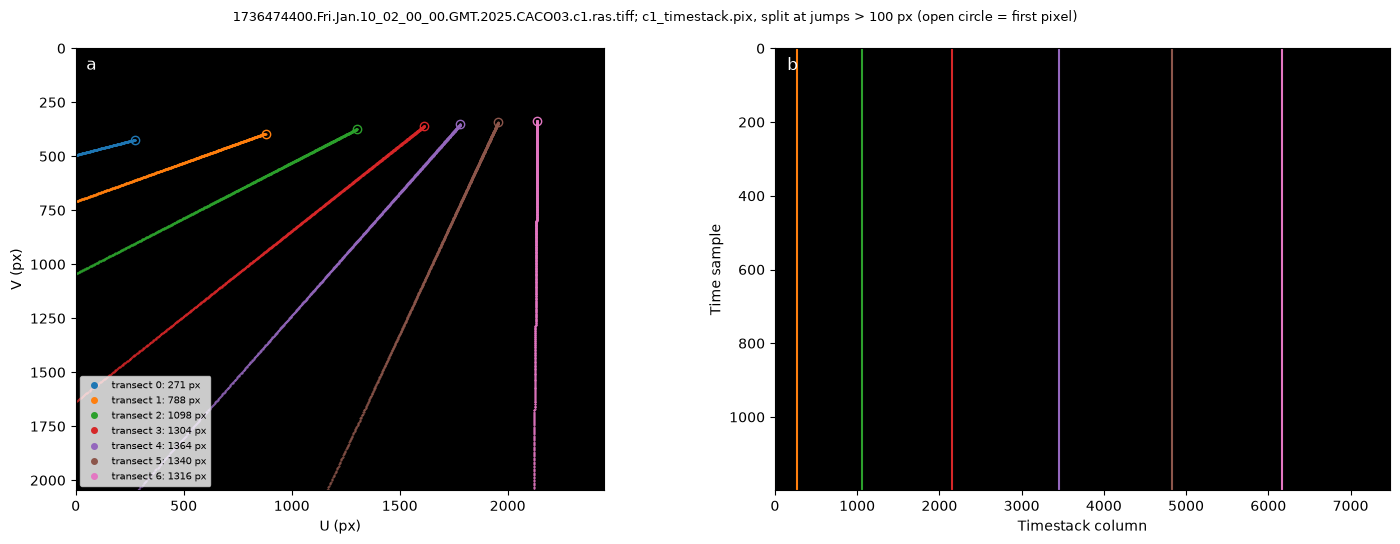

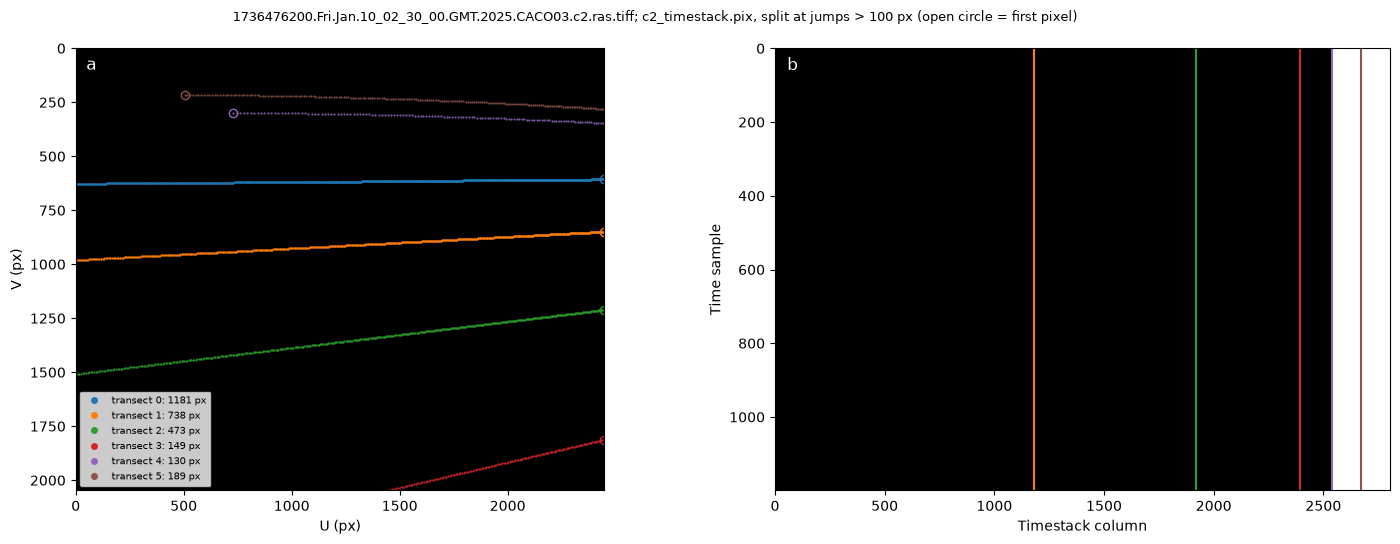

In [2]:
from IPython.display import Image, display
for p in mr.plot_pix_periods(FIG_DIR, ts, scan, table, PIX_FILES, cam_set, RUNUP):
    display(Image(str(p), width=900))
for c, g in ts.groupby('camera'):
    r = g.iloc[len(g) // 2]
    pix_path, rev = mr.pix_for(r, PIX_FILES, cam_set, RUNUP)
    fig, lens = mr.plot_pix_check(FIG_DIR / f'pix_check_{c}.png', r.path, pix_path, rev, RUNUP)
    print(f'{c}: timestack {cv2.imread(r.path).shape[1]} columns; {pix_path.name} {lens.sum()} pixels; transects {lens.tolist()}')

## Test on a few timestacks
Twelve timestacks spread over the record, with a figure for every transect: a. timestack (seaward on the left) with the
waterline, b. waterline elevation series with the water level and Stockdon levels, c. DEM profile with the swash range.
Check that the red line follows the landward edge of the swash before running everything. Results go to the same
CSV files as the full run (delete them to start over).

In [3]:
day = ts[ts.time.dt.hour.between(13, 20)]          # daytime (UTC)
test = day.iloc[np.unique(np.linspace(0, len(day) - 1, 12).astype(int))]
res = mr.process_all(test, CAL_DIR, table, PIX_FILES, DEM_DIR, scan, OUT_DIR, RUNUP, fig_dir=STACK_FIG_DIR,
                     fig_every=1, cam_set=cam_set)
cols = ['time', 'camera', 'transect', 'status', 'c_sand', 'clip_sea', 'clip_land', 'water_level',
        'z_min', 'z_med', 'z_p98', 'z_max', 'S_sig', 'R2_stockdon_z', 'beta_swash']
res[res.path.isin(test.path)][[c for c in cols if c in res]].set_index('time').round(3)

,camera,transect,status,c_sand,clip_sea,clip_land,water_level,z_min,z_med,z_p98,z_max,S_sig,R2_stockdon_z,beta_swash
time,,,,,,,,,,,,,,
2024-12-09 18:00:00,c1,NaN,width 7481 != 7610 pix,NaN,NaN,NaN,0.753,NaN,NaN,NaN,NaN,NaN,1.82,NaN
2024-12-19 15:30:00,c2,NaN,width 2541 != 2051 pix,NaN,NaN,NaN,0.753,NaN,NaN,NaN,NaN,NaN,1.82,NaN
2024-12-22 17:00:00,c2,NaN,width 2541 != 2051 pix,NaN,NaN,NaN,0.753,NaN,NaN,NaN,NaN,NaN,1.82,NaN
2025-01-01 20:00:00,c1,NaN,width 7481 != 7610 pix,NaN,NaN,NaN,0.753,NaN,NaN,NaN,NaN,NaN,1.82,NaN
2025-01-05 14:00:00,c1,NaN,no calibration,NaN,NaN,NaN,0.753,NaN,NaN,NaN,NaN,NaN,1.82,NaN
2025-01-08 15:30:00,c1,NaN,width 7481 != 7610 pix,NaN,NaN,NaN,0.753,NaN,NaN,NaN,NaN,NaN,1.82,NaN
2025-01-11 17:00:00,c1,NaN,width 7481 != 7610 pix,NaN,NaN,NaN,0.753,NaN,NaN,NaN,NaN,NaN,1.82,NaN
2025-01-14 18:30:00,c1,NaN,width 7481 != 7610 pix,NaN,NaN,NaN,0.753,NaN,NaN,NaN,NaN,NaN,1.82,NaN
2025-01-18 13:00:00,c2,NaN,width 2541 != 2051 pix,NaN,NaN,NaN,0.753,NaN,NaN,NaN,NaN,NaN,1.82,NaN


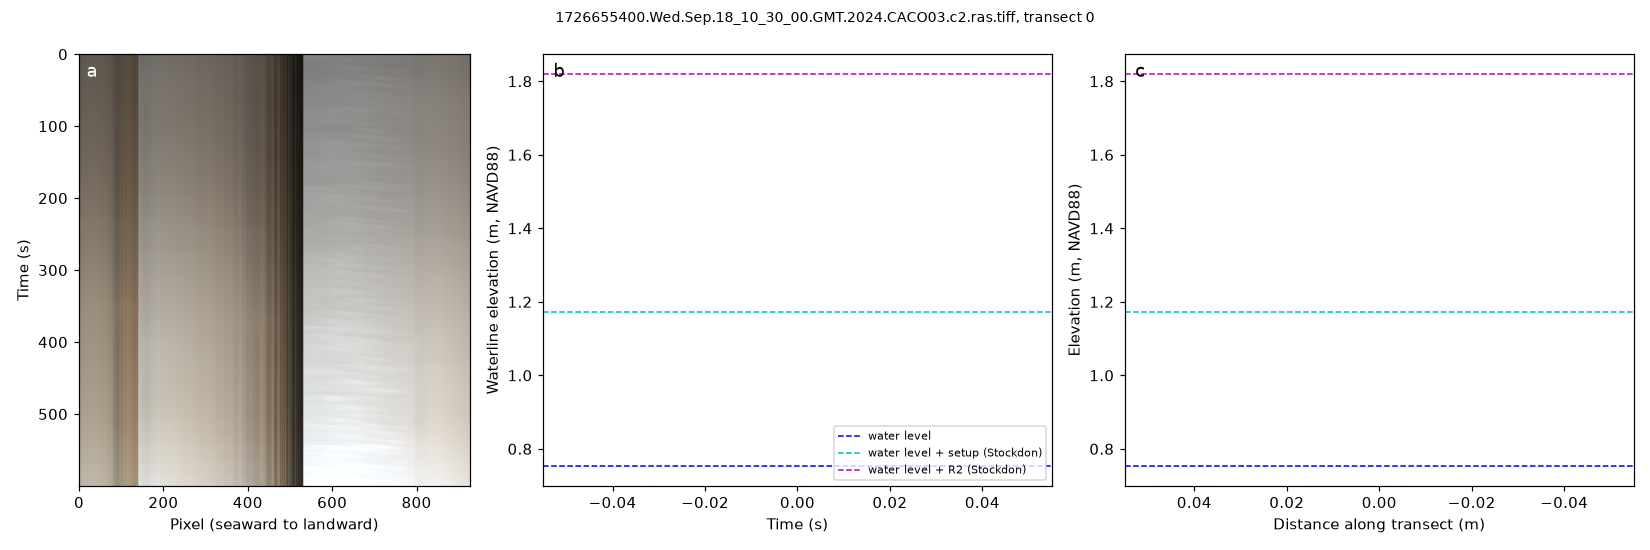

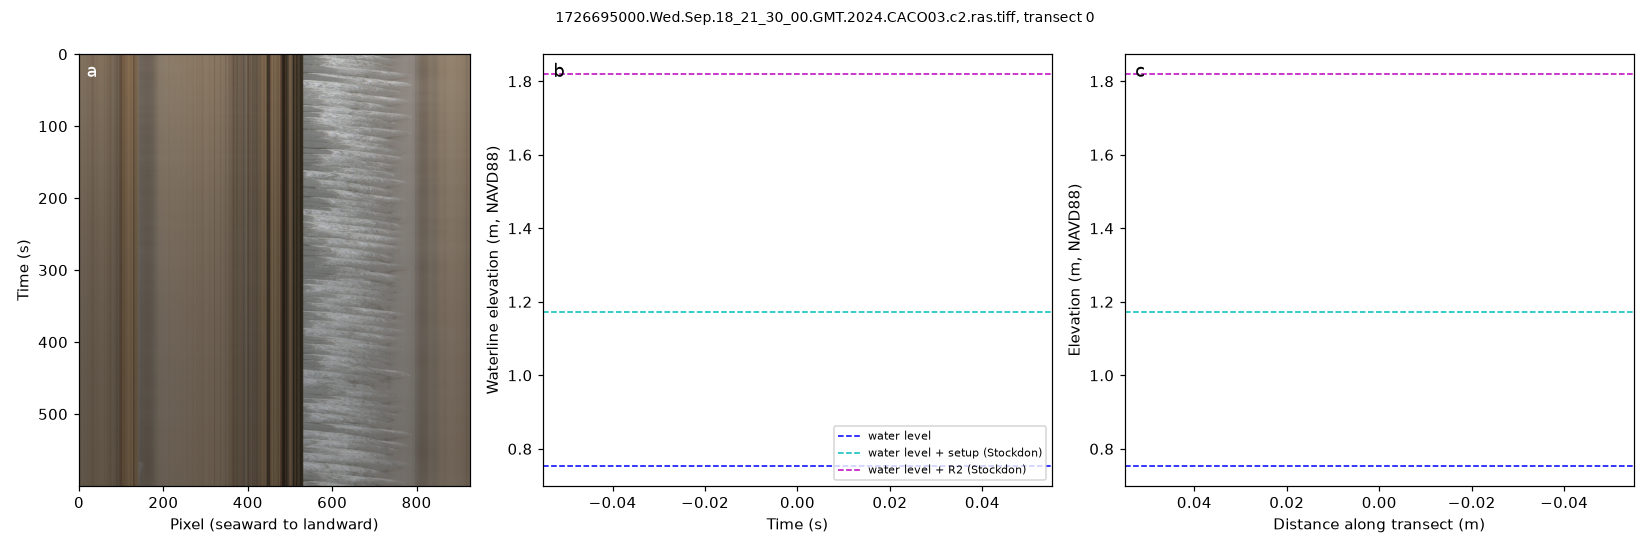

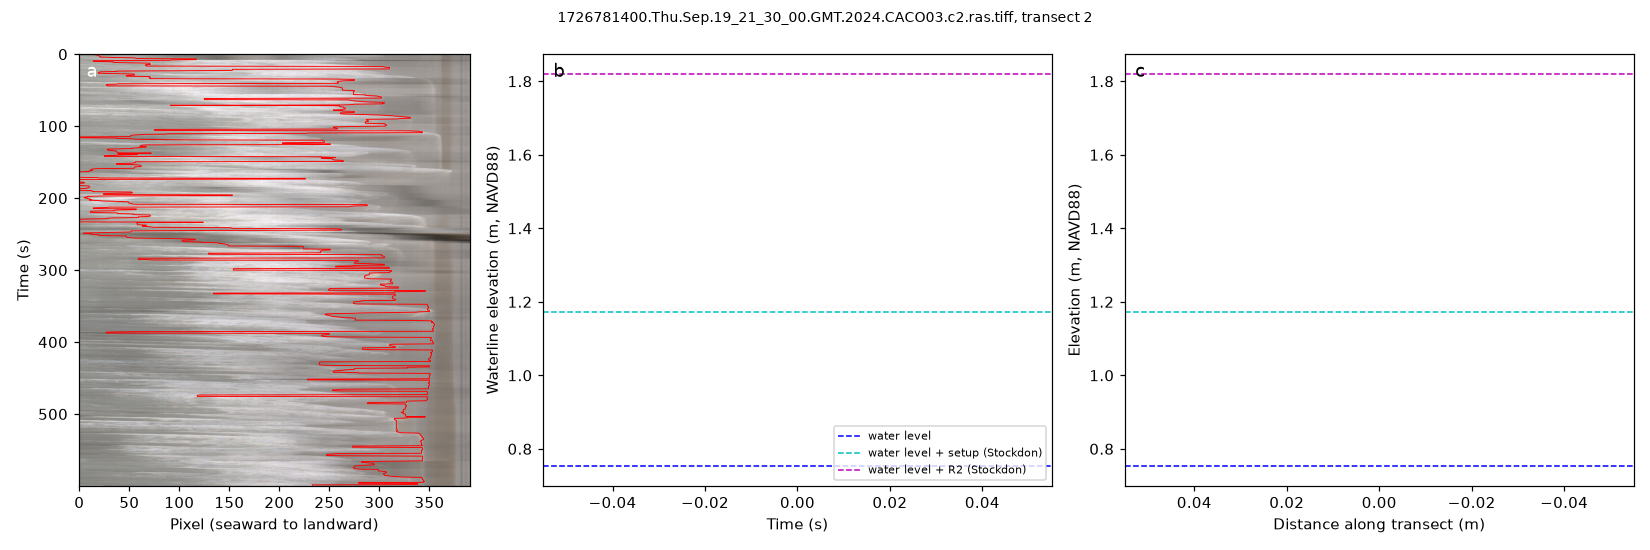

In [4]:
from IPython.display import Image, display
for p in sorted(STACK_FIG_DIR.glob('*.png'))[:3]:
    display(Image(str(p), width=1100))

## All timestacks
About 1 s per timestack (plus about 1 s per transect each new day for the profiles). Appends and resumes if rerun.
A figure every `FIG_EVERY` timestack transects.

In [5]:
FIG_EVERY = 50
res = mr.process_all(ts, CAL_DIR, table, PIX_FILES, DEM_DIR, scan, OUT_DIR, RUNUP, fig_dir=STACK_FIG_DIR,
                     fig_every=FIG_EVERY, cam_set=cam_set)
print(res.status.value_counts())

status
width 7481 != 7610 pix    893
width 2541 != 2051 pix    891
no calibration            462
unreadable                  1
Name: count, dtype: int64


## Summary figures
Time series of the waterline median, 98th percentile, and min-to-max range for each transect, with the water level and
Stockdon $R_{2\%}$ level; and, for each day, the DEM profiles with the min, median, and max waterline positions.

In [6]:
prof = pd.read_csv(OUT_DIR / 'runup_profiles.csv', parse_dates=['day'])
fig = mr.plot_series(FIG_DIR / 'runup_excursion_series.png', res, RUNUP)
for d in res[res.status == 'ok'].time.dt.floor('D').unique():
    mr.plot_day(DAY_FIG_DIR / f'runup_profiles_{d:%Y-%m-%d}.png', res, prof, d)

FileNotFoundError: [Errno 2] No such file or directory: 'F:\\crs\\proj\\2026_wl_dems\\scan\\runup_profiles.csv'

In [ ]:
ok = res[res.status == 'ok']
print(ok.groupby(['camera', 'transect'])[['eta_med', 'eta_p98', 'eta_max', 'S_sig', 'beta_swash', 'clip_sea', 'clip_land']].median().round(3))